# 05 · Catálogo de datasets públicos
Entrada: `data/external/catalogo_datasets.csv` (14 datasets; los campos sin dato quedan vacíos).

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.cluster.hierarchy import dendrogram, fcluster, linkage
from scipy.spatial.distance import squareform

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIG = ROOT / "figuras" / "05_catalogo_datasets"; OUT = ROOT / "data" / "processed"
FIG.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight"})

cat = pd.read_csv(ROOT / "data" / "external" / "catalogo_datasets.csv")
print("Datasets:", len(cat))
cat[["nombre", "anio", "modalidad", "especies", "n_muestras", "unidad_muestra", "etiqueta_cojera", "licencia"]]

Datasets: 14


,nombre,anio,modalidad,especies,n_muestras,unidad_muestra,etiqueta_cojera,licencia
0,Horse-30 / Horse-10,2021,imagen (frames de video),caballo,8114.0,frames,0,CC BY-NC 4.0
1,PFERD,2024,video multivista + mocap 3D,caballo,NaN,secuencias,0,acceso abierto (Scientific Data)
2,IMU caballo islandés - cojera inducida,2023,IMU (16 sensores 500 Hz),caballo,85.0,pruebas,1,CC BY 4.0
3,Horse Treadmill (Zúrich / hSMAL),2021,video multivista + mocap 3D,caballo,NaN,secuencias,1,no especificada (sin descarga pública)
4,AP-10K,2021,imagen,54 especies de mamíferos,10015.0,imágenes,0,CC BY 4.0
5,APT-36K,2022,video (clips de 15 frames),30 especies,36000.0,frames,0,solo investigación (frames de YouTube)
6,APTv2,2023,video (clips de 15 frames),30 especies,41235.0,frames,0,no especificada (uso académico)
7,Animal Kingdom,2022,video + frames,850 especies,33000.0,frames (pose),0,no especificada (descarga con formulario)
8,Animal-Pose,2019,imagen,5 especies (perro gato vaca caballo oveja),4000.0,imágenes,0,no especificada (uso académico)
9,TigDog,2015,video,caballo y tigre,10152.0,frames de caballo,0,no especificada (uso académico)


## 1. Faltantes y transformación

In [2]:
print((cat.isna().mean() * 100).round(0)[lambda s: s > 0])
cat["modalidad_grupo"] = np.select(
    [cat.modalidad.str.contains("IMU"), cat.modalidad.str.contains("mocap"), cat.modalidad.str.contains("video"),
     cat.modalidad.str.contains("imagen")],
    ["Sensores IMU", "Video + mocap 3D", "Video", "Imagen"], "Otro")
cat["log_muestras"] = np.log10(cat["n_muestras"])
cat["n_keypoints"] = cat["n_keypoints"].fillna(-1)  # -1 = no reportado (se excluye en la distancia)
cat["apertura"] = np.select([cat.uso_comercial_confirmado == 1, cat.acceso.str.startswith("abierto")], [2, 1], 0)

n_muestras     21.0
n_keypoints     7.0
dtype: float64


In [3]:
def gower(df, num, binar):
    n = len(df); D = np.zeros((n, n)); W = np.zeros((n, n))
    for c in num:
        x = df[c].to_numpy(float); rng = np.nanmax(x) - np.nanmin(x)
        for i in range(n):
            ok = ~np.isnan(x) & ~np.isnan(x[i])
            D[i, ok] += np.abs(x[i] - x[ok]) / rng; W[i, ok] += 1
    for c in binar:
        x = df[c].to_numpy(float)
        D += (x[:, None] != x[None, :]); W += 1
    return D / W

dfg = cat.copy()
dfg["kp"] = dfg["n_keypoints"].replace(-1, np.nan)
for m in ["Sensores IMU", "Video + mocap 3D", "Video", "Imagen"]:
    dfg[f"mod_{m}"] = (dfg.modalidad_grupo == m).astype(int)
NUM = ["anio", "log_muestras", "kp", "apertura"]
BIN = ["incluye_caballo", "solo_caballo", "etiqueta_cojera", "etiqueta_comportamiento", "video_temporal", "datos_3d"] + \
      [c for c in dfg if c.startswith("mod_")]
D = gower(dfg, NUM, BIN)

## 2. Clustering jerárquico (enlace promedio sobre Gower)

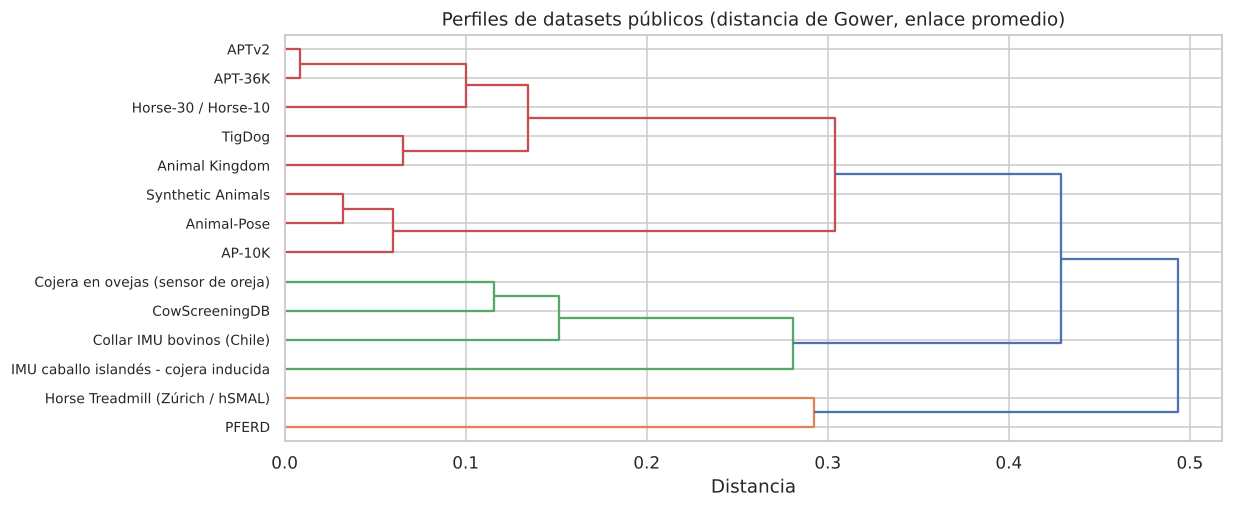

,n,datasets,pct_caballo,pct_cojera,pct_video,mediana_muestras
perfil,,,,,,
1,2,PFERD | Horse Treadmill (Zúrich / hSMAL),1.00,0.50,1.0,NaN
2,4,IMU caballo islandés - cojera inducida | CowScreeningDB | Collar IMU bovinos (Chile) | Cojera en ovejas (sensor de oreja),0.25,0.75,1.0,85.0
3,3,AP-10K | Animal-Pose | Synthetic Animals,1.00,0.00,0.0,10015.0
4,5,Horse-30 / Horse-10 | APT-36K | APTv2 | Animal Kingdom | TigDog,1.00,0.00,1.0,33000.0


In [4]:
Z = linkage(squareform(D, checks=False), method="average")
plt.figure(figsize=(11, 4.8))
dendrogram(Z, labels=cat["nombre"].tolist(), orientation="right", color_threshold=0.7 * Z[:, 2].max(), leaf_font_size=9)
plt.title("Perfiles de datasets públicos (distancia de Gower, enlace promedio)"); plt.xlabel("Distancia")
plt.savefig(FIG / "cat_dendrograma.png"); plt.show()

cat["perfil"] = fcluster(Z, 4, criterion="maxclust")
resumen = cat.groupby("perfil").agg(n=("nombre", "size"), datasets=("nombre", lambda s: " | ".join(s)),
                                   pct_caballo=("incluye_caballo", "mean"), pct_cojera=("etiqueta_cojera", "mean"),
                                   pct_video=("video_temporal", "mean"), mediana_muestras=("n_muestras", "median"))
pd.set_option("display.max_colwidth", 200)
resumen

## 3. Matriz de aptitud
Puntaje de 0 a 1 por criterio; la etiqueta de cojera y la especie pesan más.

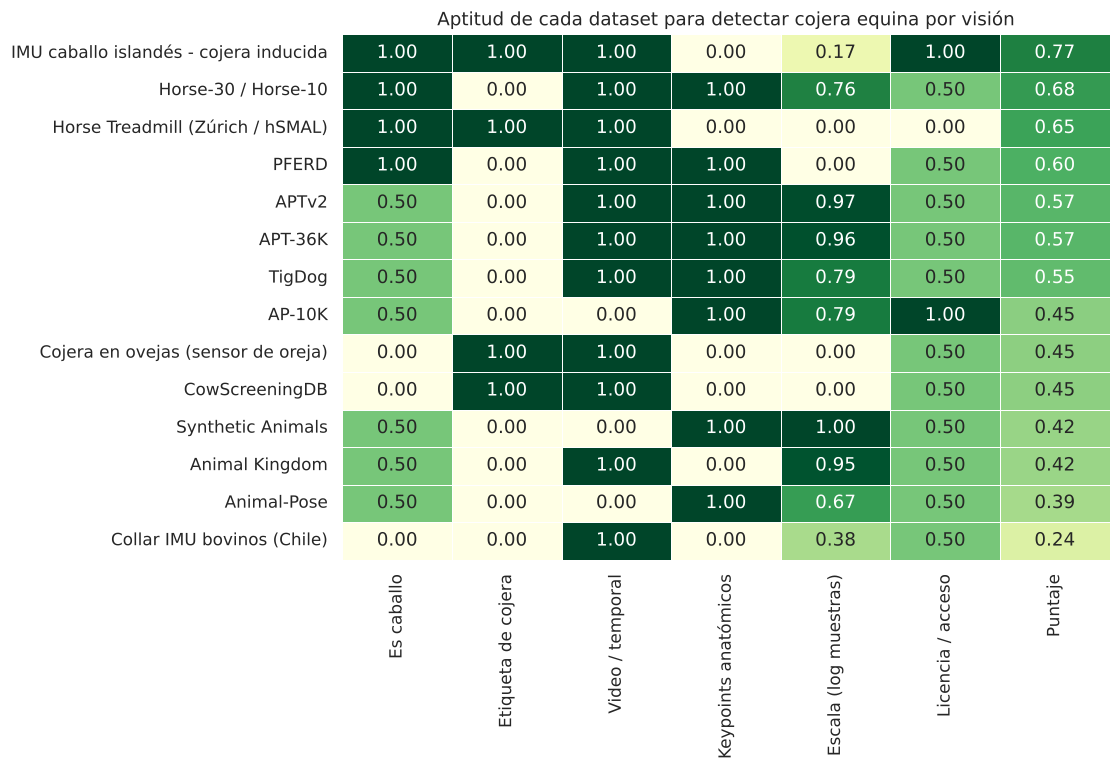

In [5]:
criterios = pd.DataFrame({k: v.to_numpy() for k, v in {
    "Es caballo": cat["solo_caballo"] * 1.0 + (cat["incluye_caballo"] - cat["solo_caballo"]) * 0.5,
    "Etiqueta de cojera": cat["etiqueta_cojera"].astype(float),
    "Video / temporal": cat["video_temporal"].astype(float),
    "Keypoints anatómicos": (cat["n_keypoints"] > 0).astype(float),
    "Escala (log muestras)": ((cat["log_muestras"] - cat["log_muestras"].min()) /
                              (cat["log_muestras"].max() - cat["log_muestras"].min())).fillna(0),
    "Licencia / acceso": cat["apertura"] / 2,
}.items()}, index=cat["nombre"])
pesos = pd.Series({"Es caballo": .25, "Etiqueta de cojera": .25, "Video / temporal": .15,
                   "Keypoints anatómicos": .15, "Escala (log muestras)": .1, "Licencia / acceso": .1})
criterios["Puntaje"] = criterios[pesos.index].mul(pesos).sum(axis=1)
criterios = criterios.sort_values("Puntaje", ascending=False)
plt.figure(figsize=(9, 6.2))
sns.heatmap(criterios, annot=True, fmt=".2f", cmap="YlGn", cbar=False, linewidths=.5)
plt.title("Aptitud de cada dataset para detectar cojera equina por visión"); plt.ylabel("")
plt.savefig(FIG / "cat_matriz_aptitud.png"); plt.show()

## 4. Conteo del vacío

In [6]:
vacio = pd.Series({
    "Datasets con caballos": int(cat.incluye_caballo.sum()),
    "…con etiqueta de cojera": int((cat.incluye_caballo & cat.etiqueta_cojera).sum()),
    "…con cojera + video público": int((cat.incluye_caballo & cat.etiqueta_cojera & cat.video_temporal &
                                        cat.modalidad_grupo.isin(["Video", "Video + mocap 3D"]) & cat.acceso.str.startswith("abierto")).sum()),
    "…con cojera y licencia comercial": int((cat.incluye_caballo & cat.etiqueta_cojera & (cat.uso_comercial_confirmado == 1)).sum()),
})
vacio.to_frame("n")

,n
Datasets con caballos,11
…con etiqueta de cojera,2
…con cojera + video público,0
…con cojera y licencia comercial,1


In [7]:
cat.to_csv(OUT / "catalogo_datasets_perfilado.csv", index=False)
criterios.to_csv(OUT / "catalogo_aptitud.csv")
print("Exportado.")

Exportado.
